# Developed-Markets Equity Scorecard — CRISIL assignment (final submission, v14)
**Objective (brief):** a scorecard for the **US, Eurozone, UK, Switzerland and Japan** that identifies markets likely to out- or under-perform over the next **3–6 months**.

| Section | Brief requirement |
|---|---|
| 1 | Data and as-of date |
| 2 | Step 1 — Signal construction (one signal per pillar) |
| 3 | Step 2 — Predictive power assessment |
| 4 | Step 3 — Scorecard construction (pillar scores, aggregate scores, rankings) |
| 5 | Step 4 — Backtest of the scorecard |
| 6 | Step 5 — Investment view |
| 7 | Exports (CSV) and slide figures |

**Primary product:** the four-pillar scorecard. A **companion** FCI-only model is shown separately because it is the only pillar with supportive (provisional) evidence.
**Run:** place the six supplied workbooks in `data/raw/` and run all cells. The as-of date is detected automatically as the last month in which all five markets report — updated Bloomberg exports with the same tickers refresh every number.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata
from IPython.display import display
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 230; pd.options.display.max_columns = 30
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v14'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']; SEED = 7; NBOOT = 2000
COL = {'US': '#1f4e79', 'Eurozone': '#2e8b57', 'UK': '#c0504d', 'Switzerland': '#e69f00', 'Japan': '#7f6aa8'}
PCOL = {'Macro': '#1f4e79', 'Micro': '#2e8b57', 'Valuation': '#e69f00', 'Technical': '#7f6aa8'}
FIG = {}            # every number that appears on a slide is recorded here and exported to ppt_figures.json

## 1. Data and as-of date

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  pe='BEst P/E Ratio', eps='Monthly_EPS', fci=('GSFCI Index', -1),   fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', pe='BEst P/E Ratio', eps='BEst EPS',    fci=('BFCIEU Index', +1),  fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  pe='BEst P/E Ratio', eps='BEst EPS',    fci=('GSGBFCI Index', -1), fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  pe='BEst P/E Ratio', eps='BEst EPS',    fci=('GSEAFCI Index', -1), fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', pe='BEst P/E Ratio', eps='BEst EPS',    fci=('GSJPFCI Index', -1), fx=('USDJPY BGN Curncy', 'invert')),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
RAWX = {c: monthly(pd.read_excel(ROOT/'data'/'raw'/SPEC[c]['file'])) for c in COUNTRIES}
def col(c, k):
    s = SPEC[c]; d = RAWX[c]
    if k == 'fci': return s['fci'][1] * d[s['fci'][0]]               # oriented: higher = EASIER conditions
    if k == 'fx': return pd.Series(1.0, index=d.index) if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return d[s[k]]
IDX = pd.period_range(max(col(c, 'pe').first_valid_index() for c in COUNTRIES), min(RAWX[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, FCI, FX = [pd.DataFrame({c: col(c, k) for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'fci', 'fx')]
PX = PE * EPS; PX_USD = PX * FX; R = PX_USD.pct_change()              # implied index level; USD monthly price return
AS_OF = IDX[-1]
COV = pd.DataFrame({'workbook': {c: SPEC[c]['file'] for c in COUNTRIES}, 'P/E': {c: SPEC[c]['pe'] for c in COUNTRIES}, 'EPS': {c: SPEC[c]['eps'] for c in COUNTRIES},
                    'FCI': {c: SPEC[c]['fci'][0] for c in COUNTRIES}, 'FX': {c: (SPEC[c]['fx'] or ('USD',))[0] for c in COUNTRIES},
                    'last date in workbook': {c: str(pd.to_datetime(RAWX[c]['Date']).max().date()) for c in COUNTRIES}})
display(COV)
print(f'Common monthly panel: {IDX[0]} -> {AS_OF} ({len(IDX)} months). AS-OF DATE = {AS_OF} (the US workbook ends 30-Apr-2026).')
print('DISCLOSURE: the supplied data end in April 2026. Every "current" reading in this notebook is AS OF 30-APR-2026, not today.')
FIG['as_of'] = str(AS_OF); FIG['panel'] = f'{IDX[0]} to {AS_OF}'

,workbook,P/E,EPS,FCI,FX,last date in workbook
US,US_raw_data.xlsx,BEst P/E Ratio,Monthly_EPS,GSFCI Index,USD,2026-04-30
Eurozone,EUR_raw_data.xlsx,BEst P/E Ratio,BEst EPS,BFCIEU Index,EURUSD BGN Curncy,2026-06-29
UK,UK_raw_data.xlsx,BEst P/E Ratio,BEst EPS,GSGBFCI Index,GBPUSD BGN Curncy,2026-07-02
Switzerland,CH_raw_data.xlsx,BEst P/E Ratio,BEst EPS,GSEAFCI Index,USDCHF Curncy,2026-07-14
Japan,JPY_raw_data.xlsx,BEst P/E Ratio,BEst EPS,GSJPFCI Index,USDJPY BGN Curncy,2026-06-29


Common monthly panel: 2005-12 -> 2026-04 (245 months). AS-OF DATE = 2026-04 (the US workbook ends 30-Apr-2026).
DISCLOSURE: the supplied data end in April 2026. Every "current" reading in this notebook is AS OF 30-APR-2026, not today.


## 2. Step 1 — Signal construction
One indicator per pillar. Each is computed per market at month-end t, then **z-scored across the five markets** that month: $z_{i,t} = (x_{i,t}-\bar x_t)/s_t$. A higher z is always more attractive.

In [3]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
own_sd = lambda d, w=36: d / d.expanding(w).std()
z_own = lambda x, w=60: (x - x.expanding(w).mean()) / x.expanding(w).std()
PILLARS = ['Macro', 'Micro', 'Valuation', 'Technical']
RAWSIG = {'Macro': own_sd(FCI - FCI.shift(6)),
          'Micro': EPS / EPS.shift(6) - 1,
          'Valuation': -z_own(PE.div(PE.mean(axis=1), axis=0)),
          'Technical': -PX.pct_change().rolling(12).std()}
Z = {p: cs_z(RAWSIG[p]) for p in PILLARS}
SIGDOC = pd.DataFrame([
 {'pillar': 'Macro', 'indicator': 'FCI 6M easing',
  'economic rationale': 'Easier financing conditions (tighter spreads, lower rates/vol, weaker currency, higher equity prices) support earnings and risk appetite with a lag; markets where conditions ease most should outperform.',
  'construction': '(FCI_t − FCI_t−6) ÷ expanding sd of that 6M change; FCI oriented so higher = easier', 'direction': 'larger easing ⇒ more attractive',
  'lookback': '6 months (change); expanding sd, ≥36 obs burn-in', 'standardisation': 'own-history scaling (removes index-unit differences), then cross-sectional z',
  'data source': 'GSFCI (US), BFCIEU (EZ), GSGBFCI (UK), GSEAFCI (CH - euro-area index), GSJPFCI (JP)'},
 {'pillar': 'Micro', 'indicator': 'EPS revisions 6M',
  'economic rationale': 'Analysts revise forecasts gradually (anchoring), so upgrades tend to persist and prices under-react; markets with rising forward earnings should outperform.',
  'construction': 'EPS_t / EPS_t−6 − 1 (12M-forward consensus EPS)', 'direction': 'stronger upgrades ⇒ more attractive',
  'lookback': '6 months', 'standardisation': 'cross-sectional z',
  'data source': 'Monthly_EPS (US), BEst EPS (EZ, UK, CH, JP)'},
 {'pillar': 'Valuation', 'indicator': 'P/E relative to peers',
  'economic rationale': 'Relative cheapness should mean-revert: a market trading at a discount to its peers versus its own history should re-rate.',
  'construction': '−z_own(PE_t / mean PE of the 5 markets), expanding z over own history', 'direction': 'cheaper vs peers (vs own history) ⇒ more attractive',
  'lookback': 'expanding window, ≥60 obs burn-in', 'standardisation': 'own-history z (removes structural sector-mix premia), then cross-sectional z',
  'data source': 'BEst P/E Ratio (all five)'},
 {'pillar': 'Technical', 'indicator': 'Low realised volatility 12M',
  'economic rationale': 'Low-volatility anomaly: lower-risk assets have historically delivered better risk-adjusted returns; calm markets also signal lower risk premia shocks.',
  'construction': '−sd of the last 12 monthly local-currency index returns, index = BEst P/E × forward EPS', 'direction': 'lower volatility ⇒ more attractive',
  'lookback': '12 months', 'standardisation': 'cross-sectional z',
  'data source': 'Implied index level from BEst P/E Ratio × EPS (see validity checks below)'},
]).set_index('pillar')
display(SIGDOC)
SIGDOC.to_csv(OUT/'signal_definitions.csv')
print('First month each signal is defined for all five markets:', {p: str(Z[p].dropna().index.min()) for p in PILLARS})

,indicator,economic rationale,construction,direction,lookback,standardisation,data source
pillar,,,,,,,
Macro,FCI 6M easing,"Easier financing conditions (tighter spreads, ...",(FCI_t − FCI_t−6) ÷ expanding sd of that 6M ch...,larger easing ⇒ more attractive,"6 months (change); expanding sd, ≥36 obs burn-in",own-history scaling (removes index-unit differ...,"GSFCI (US), BFCIEU (EZ), GSGBFCI (UK), GSEAFCI..."
Micro,EPS revisions 6M,Analysts revise forecasts gradually (anchoring...,EPS_t / EPS_t−6 − 1 (12M-forward consensus EPS),stronger upgrades ⇒ more attractive,6 months,cross-sectional z,"Monthly_EPS (US), BEst EPS (EZ, UK, CH, JP)"
Valuation,P/E relative to peers,Relative cheapness should mean-revert: a marke...,"−z_own(PE_t / mean PE of the 5 markets), expan...",cheaper vs peers (vs own history) ⇒ more attra...,"expanding window, ≥60 obs burn-in",own-history z (removes structural sector-mix p...,BEst P/E Ratio (all five)
Technical,Low realised volatility 12M,Low-volatility anomaly: lower-risk assets have...,−sd of the last 12 monthly local-currency inde...,lower volatility ⇒ more attractive,12 months,cross-sectional z,Implied index level from BEst P/E Ratio × EPS ...


First month each signal is defined for all five markets: {'Macro': '2009-05', 'Micro': '2006-06', 'Valuation': '2010-11', 'Technical': '2006-12'}


### Is the technical signal built on genuine price information?
1. **The supplied "Price" workbook contains P/E ratios**, not index levels. It is labelled with the brief's price tickers (SPX, MXEM, MXGB, MXCH, MXJP), but its values equal the BEst P/E fields — so no independent price series was supplied.
2. **Index level is recovered exactly from P/E × EPS**, because P/E ≡ Price / EPS. This is an identity, not a model.
3. **Check against the real index:** US implied monthly returns vs published S&P 500 monthly price returns for eight well-known months (reference values entered manually from public records — not part of the supplied data).
4. **Not an earnings restatement:** realised volatility is a property of the price *path*; regress it on EPS revisions to confirm it carries little earnings information.

In [4]:
pf = pd.read_excel(ROOT/'data'/'raw'/'Price_data_all_countries.xlsx')
rows = []
for dcol, vcol in [('US', 'SPX Index'), ('Eurozone ', 'MXEM Index'), ('UK', 'MXGB Index'), ('Switzerland', 'MXCH Index'), ('Japan', 'MXJP Index')]:
    s = pf[[dcol, vcol]].dropna(); s.index = pd.to_datetime(s[dcol]).dt.to_period('M'); s = s[~s.index.duplicated(keep='last')][vcol]
    j = pd.concat([s.rename('f'), PE[dcol.strip()].rename('pe')], axis=1).dropna()
    rows.append({'market': dcol.strip(), 'price-file column': vcol, 'months compared': len(j), 'median |file − BEst P/E|': (j.f - j.pe).abs().median(), 'file value range': f'{j.f.min():.1f}–{j.f.max():.1f}'})
display(pd.DataFrame(rows).set_index('market'))
RLOC = PX.pct_change()
known = {'2008-09': -9.08, '2008-10': -16.94, '2009-02': -10.99, '2011-09': -7.18, '2018-12': -9.18, '2020-03': -12.51, '2020-04': 12.68, '2022-04': -8.80}
SPXCHK = pd.DataFrame([{'month': k, 'implied US %': RLOC['US'].loc[pd.Period(k, 'M')] * 100, 'published S&P 500 %': v} for k, v in known.items()]).set_index('month')
SPXCHK['difference (pp)'] = SPXCHK['implied US %'] - SPXCHK['published S&P 500 %']; display(SPXCHK.round(2))
FIG['spx_check_mad_pp'] = float(SPXCHK['difference (pp)'].abs().mean())
EB = pd.concat({'r3': cs_z(EPS / EPS.shift(3) - 1).stack(), 'r6': Z['Micro'].stack(), 'r12': cs_z(EPS / EPS.shift(12) - 1).stack()}, axis=1)
jj = pd.concat([Z['Technical'].stack().rename('y'), EB], axis=1).dropna()
r2_tech = sm.OLS(jj.y.values, sm.add_constant(jj[['r3', 'r6', 'r12']].values)).fit().rsquared
print(f'Mean |implied − published| = {FIG["spx_check_mad_pp"]:.2f} pp. R² of the technical signal on EPS revisions (3/6/12M) = {r2_tech:.1%} -> genuine price-path information.')
print(f'Annualised volatility of the implied indices: ' + ', '.join(f'{c} {RLOC[c].std() * np.sqrt(12):.1%}' for c in COUNTRIES) + ' (typical of DM equity indices).')
print('LIMITATIONS: price return only (no dividends); local-currency returns for the volatility signal; the EZ/UK/CH/JP reconstructions cannot be checked against a published index with the supplied data.')
FIG['tech_r2_on_eps'] = float(r2_tech)

,price-file column,months compared,median |file − BEst P/E|,file value range
market,,,,
US,SPX Index,245,0.004,10.5–22.9
Eurozone,MXEM Index,245,0.000,8.0–18.3
UK,MXGB Index,245,0.000,7.7–16.1
Switzerland,MXCH Index,245,0.000,10.4–20.4
Japan,MXJP Index,245,0.000,11.1–39.2


,implied US %,published S&P 500 %,difference (pp)
month,,,
2008-09,-9.090,-9.080,-0.010
2008-10,-16.970,-16.940,-0.030
2009-02,-11.000,-10.990,-0.010
2011-09,-7.170,-7.180,0.010
2018-12,-9.350,-9.180,-0.170
2020-03,-12.530,-12.510,-0.020
2020-04,12.700,12.680,0.020
2022-04,-8.830,-8.800,-0.030


Mean |implied − published| = 0.04 pp. R² of the technical signal on EPS revisions (3/6/12M) = 1.5% -> genuine price-path information.
Annualised volatility of the implied indices: US 15.2%, Eurozone 16.5%, UK 13.1%, Switzerland 12.5%, Japan 17.2% (typical of DM equity indices).
LIMITATIONS: price return only (no dividends); local-currency returns for the volatility signal; the EZ/UK/CH/JP reconstructions cannot be checked against a published index with the supplied data.


## 3. Step 2 — Predictive power assessment
**Test:** each month, the Spearman rank correlation (IC) between a pillar's scores and the next 3- or 6-month USD relative return (market return minus the 5-market average). The reported IC is the average over months.
**Windows:** discovery = signal months up to 2016-12; a 6-month embargo follows; validation = 2017-07 onward.
**Inference (all one-sided, H0: IC ≤ 0):**
* 95% CI from a moving-block bootstrap (block = 2 × horizon, because overlapping returns are autocorrelated).
* HAC (Newey-West) t-statistic, lags = horizon.
* Block-permutation p: country labels shuffled in horizon-length blocks, 5,000 draws.

In [5]:
def fwd(h): r = PX_USD.shift(-h) / PX_USD - 1; return r.sub(r.mean(axis=1), axis=0)
TG = {3: fwd(3), 6: fwd(6)}
EMB_END, VAL_START = pd.Period('2016-12', 'M'), pd.Period('2017-07', 'M')
def unit_ranks(A):
    r = rankdata(A, axis=-1) - 3.0; return r / np.sqrt((r ** 2).sum(-1, keepdims=True))
def ic_series(S, Y):
    s = S.to_numpy(float); y = Y.reindex(S.index).to_numpy(float); ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    return pd.Series((unit_ranks(s[ok]) * unit_ranks(y[ok])).sum(1), index=S.index[ok])
def contributions(S, Y, months):
    s = S.reindex(months).to_numpy(float); y = Y.reindex(months).to_numpy(float)
    return pd.DataFrame(unit_ranks(s) * unit_ranks(y), index=months, columns=COUNTRIES)     # sums exactly to the monthly IC
def hac_t(x, lags): return float(sm.OLS(np.asarray(x), np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0])
def mbb_ci(x, L, n=NBOOT, seed=SEED):
    x = np.asarray(x); T = len(x); rng = np.random.default_rng(seed); nb = int(np.ceil(T / L))
    st = rng.integers(0, T - L + 1, (n, nb)); m = x[(st[:, :, None] + np.arange(L)).reshape(n, -1)[:, :T]].mean(1)
    return np.percentile(m, [2.5, 97.5])
def perm_p(S, Y, months, h, n=5000, seed=SEED):
    RS = unit_ranks(S.reindex(months).to_numpy(float)); RY = unit_ranks(Y.reindex(months).to_numpy(float)); T = len(months); blk = np.arange(T) // h
    P = np.random.default_rng(seed).permuted(np.tile(np.arange(5), (n, blk.max() + 1, 1)), axis=2)[:, blk, :]
    null = (RS[None] * np.take_along_axis(np.broadcast_to(RY, (n, T, 5)), P, axis=2)).sum(-1).mean(-1)
    return (1 + (null >= (RS * RY).sum(-1).mean()).sum()) / (1 + n)
rows = []; CONTRIB = []
for p in PILLARS:
    for h in (3, 6):
        ic = ic_series(Z[p], TG[h])
        for wl, sel in (('discovery', ic.index <= EMB_END), ('validation', ic.index >= VAL_START), ('full', ic.index >= ic.index.min())):
            x = ic[sel]; lo, hi = mbb_ci(x.values, 2 * h)
            rows.append({'pillar': p, 'horizon': f'{h}M', 'window': wl, 'from': str(x.index.min()), 'to': str(x.index.max()), 'months': len(x),
                         'IC': x.mean(), 'CI 2.5%': lo, 'CI 97.5%': hi, 'HAC t': hac_t(x.values, h), 'perm p': perm_p(Z[p], TG[h], x.index, h), 'hit rate (IC>0)': (x > 0).mean()})
            if wl != 'full':
                c = contributions(Z[p], TG[h], x.index).mean()
                CONTRIB.append({'pillar': p, 'horizon': f'{h}M', 'window': wl, **c.to_dict(), 'total = IC': c.sum()})
PP = pd.DataFrame(rows).set_index(['pillar', 'horizon', 'window'])
display(PP.style.format({'IC': '{:+.3f}', 'CI 2.5%': '{:+.3f}', 'CI 97.5%': '{:+.3f}', 'HAC t': '{:+.2f}', 'perm p': '{:.3f}', 'hit rate (IC>0)': '{:.0%}'}))
PP.to_csv(OUT/'predictive_power.csv')
CT = pd.DataFrame(CONTRIB).set_index(['pillar', 'horizon', 'window'])
print('Country contributions to the mean IC (exact decomposition: the five columns sum to the IC):')
display(CT.style.format('{:+.3f}').background_gradient(axis=None, cmap='RdBu', vmin=-.08, vmax=.08, subset=COUNTRIES))
CT.to_csv(OUT/'country_contributions.csv')

Country contributions to the mean IC (exact decomposition: the five columns sum to the IC):


### Classification (criteria fixed before reading the table)
| Class | Rule |
|---|---|
| **RETAIN** | Validation IC > 0 at **both** 3M and 6M, bootstrap CI excludes 0 at both, and the result survives the multiple-testing adjustment |
| **PROVISIONAL** | Validation IC > 0 at both horizons and permutation p < 0.05 at ≥ 1 horizon, but the CI includes 0 or it fails the multiple-testing adjustment |
| **REJECTED** | Validation IC ≤ 0 at either horizon, or no horizon significant |

**Multiple-testing caveat (applies to every pillar).** These four indicators were chosen during research that tested many alternatives (~25,500 cumulative selection decisions across v1–v13).
* The v11 audit measured the selection-adjusted p-values for FCI and EPS against the family of variants they were chosen from: **0.16–0.20**.
* In samples this short with overlapping returns, a nominal 5% HAC test rejects **6–9%** of the time under a true null (v11 simulation).
* The validation window has been examined across many iterations, so it is **not** a fresh holdout.

**No pillar can be described as statistically significant.**

,indicator,validation IC 3M,validation IC 6M,perm p 3M,perm p 6M,classification,interpretation
Macro,FCI 6M easing,0.127,0.173,0.015,0.018,PROVISIONAL,Positive in both windows and both horizons; th...
Micro,EPS revisions 6M,0.131,0.074,0.019,0.195,PROVISIONAL,"Positive at 3M, weak at 6M. About half of the ..."
Valuation,P/E relative to peers,-0.108,-0.112,0.951,0.878,REJECTED,"Positive in discovery, negative in validation...."
Technical,Low realised volatility 12M,-0.066,-0.029,0.850,0.626,REJECTED,"Positive in discovery, negative in validation...."


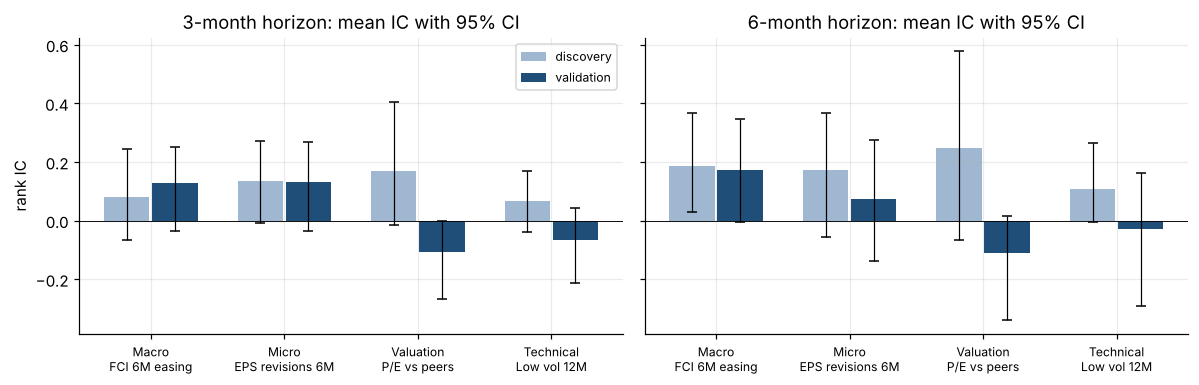

In [6]:
def classify(p):
    v3, v6 = PP.loc[(p, '3M', 'validation')], PP.loc[(p, '6M', 'validation')]
    if v3.IC <= 0 or v6.IC <= 0 or min(v3['perm p'], v6['perm p']) >= 0.05: return 'REJECTED'
    if v3['CI 2.5%'] > 0 and v6['CI 2.5%'] > 0: return 'RETAIN (subject to multiple-testing check)'
    return 'PROVISIONAL'
NOTE = {'Macro': 'Positive in both windows and both horizons; the strongest pillar, but not significant after selection. 3M result depends on the US; 6M does not.',
        'Micro': 'Positive at 3M, weak at 6M. About half of the 3M IC is a persistent tilt toward the US and Japan rather than timing (v11).',
        'Valuation': 'Positive in discovery, negative in validation. Cheap markets stayed cheap: the earnings leg offset any re-rating.',
        'Technical': 'Positive in discovery, negative in validation. Not explained by market direction; no country-level mechanism identified.'}
CLS = pd.DataFrame({p: {'indicator': SIGDOC.loc[p, 'indicator'], 'validation IC 3M': PP.loc[(p, '3M', 'validation'), 'IC'], 'validation IC 6M': PP.loc[(p, '6M', 'validation'), 'IC'],
                        'perm p 3M': PP.loc[(p, '3M', 'validation'), 'perm p'], 'perm p 6M': PP.loc[(p, '6M', 'validation'), 'perm p'],
                        'classification': classify(p), 'interpretation': NOTE[p]} for p in PILLARS}).T
display(CLS); CLS.to_csv(OUT/'signal_classification.csv')
FIG['ic'] = {p: {f'{w} {h}M': float(PP.loc[(p, f'{h}M', w), 'IC']) for w in ('discovery', 'validation') for h in (3, 6)} for p in PILLARS}
FIG['ic_ci_val'] = {p: {f'{h}M': [float(PP.loc[(p, f'{h}M', 'validation'), 'CI 2.5%']), float(PP.loc[(p, f'{h}M', 'validation'), 'CI 97.5%'])] for h in (3, 6)} for p in PILLARS}
FIG['perm_p_val'] = {p: {f'{h}M': float(PP.loc[(p, f'{h}M', 'validation'), 'perm p']) for h in (3, 6)} for p in PILLARS}
FIG['classification'] = CLS['classification'].to_dict()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, h in zip(axs, (3, 6)):
    xx = np.arange(4)
    for k, (w, off) in enumerate((('discovery', -.18), ('validation', .18))):
        v = [PP.loc[(p, f'{h}M', w), 'IC'] for p in PILLARS]; lo = [PP.loc[(p, f'{h}M', w), 'CI 2.5%'] for p in PILLARS]; hi = [PP.loc[(p, f'{h}M', w), 'CI 97.5%'] for p in PILLARS]
        ax.bar(xx + off, v, .34, color=['#9fb7d0', '#1f4e79'][k], label=w, yerr=[np.array(v) - lo, np.array(hi) - v], capsize=3, error_kw={'lw': .8})
    ax.axhline(0, c='k', lw=.6); ax.set_xticks(xx); ax.set_xticklabels(['Macro\nFCI 6M easing', 'Micro\nEPS revisions 6M', 'Valuation\nP/E vs peers', 'Technical\nLow vol 12M'], fontsize=8); ax.set_title(f'{h}-month horizon: mean IC with 95% CI')
axs[0].legend(fontsize=8); axs[0].set_ylabel('rank IC'); plt.tight_layout(); plt.savefig(CH/'ic_by_pillar.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. Step 3 — Scorecard construction
* **Pillar score** = the pillar indicator's cross-sectional z-score (five markets, each month).
* **Aggregate country score** = equal-weight average of the four pillar scores (25% each). Each pillar's **contribution** to the aggregate = 0.25 × its z.
* **Ranking** = 1 (most attractive) … 5 by aggregate score.
* **Why equal weights:** the brief asks for a four-pillar scorecard, and no pillar has validated evidence that would justify estimated weights. Weights fitted to historical ICs would be in-sample optimisation.
* **Weak-indicator flags** (from §3) are carried on every output: Valuation and Technical are REJECTED predictors; they remain in the scorecard because the brief requires all four pillars, and their effect is shown separately in the backtest attribution (§5).
* **Companion model (separate):** FCI-only score = the Macro z alone — the one pillar with consistent (provisional) evidence.

In [7]:
AGG = (sum(Z[p] for p in PILLARS) / 4)
AGG = AGG.where(pd.concat([Z[p].notna().all(axis=1) for p in PILLARS], axis=1).all(axis=1), axis=0)
RANK = AGG.rank(axis=1, ascending=False); COMP = Z['Macro']; RANK_C = COMP.rank(axis=1, ascending=False)
print(f'Aggregate score defined from {AGG.dropna().index.min()} (the valuation z-score needs 60 months of history).')
HIST = []
for t in AGG.dropna().index:
    for c in COUNTRIES:
        HIST.append({'month': str(t), 'country': c, **{f'{p} score': Z[p].loc[t, c] for p in PILLARS}, **{f'{p} contribution': Z[p].loc[t, c] / 4 for p in PILLARS},
                     'aggregate score': AGG.loc[t, c], 'rank': int(RANK.loc[t, c]),
                     'scorecard call': 'OVERWEIGHT' if RANK.loc[t, c] <= 2 else ('UNDERWEIGHT' if RANK.loc[t, c] >= 4 else 'NEUTRAL'),
                     'companion FCI-only score': COMP.loc[t, c], 'companion rank': int(RANK_C.loc[t, c]),
                     'realised next-3M relative USD return': TG[3].loc[t, c], 'realised next-6M relative USD return': TG[6].loc[t, c]})
HIST = pd.DataFrame(HIST); HIST.to_csv(OUT/'scorecard_history.csv', index=False)
ic_agg = {h: ic_series(AGG, TG[h]) for h in (3, 6)}
rows = []
for h in (3, 6):
    for wl, sel in (('discovery', ic_agg[h].index <= EMB_END), ('validation', ic_agg[h].index >= VAL_START)):
        x = ic_agg[h][sel]; lo, hi = mbb_ci(x.values, 2 * h)
        rows.append({'score': 'Aggregate (4-pillar)', 'horizon': f'{h}M', 'window': wl, 'IC': x.mean(), 'CI 2.5%': lo, 'CI 97.5%': hi, 'HAC t': hac_t(x.values, h), 'perm p': perm_p(AGG, TG[h], x.index, h)})
AGGIC = pd.DataFrame(rows).set_index(['score', 'horizon', 'window']); display(AGGIC.round(3)); AGGIC.to_csv(OUT/'aggregate_score_ic.csv')
FIG['agg_ic'] = {f'{w} {h}': float(AGGIC.loc[('Aggregate (4-pillar)', h, w), 'IC']) for h in ('3M', '6M') for w in ('discovery', 'validation')}
print('The equal-weight aggregate inherits the two rejected pillars: its validation IC is shown above and explained in §5.')

Aggregate score defined from 2010-11 (the valuation z-score needs 60 months of history).


IC  CI 2.5%  CI 97.5%  HAC t  perm p
score                horizon window                                             
Aggregate (4-pillar) 3M      discovery   0.216    0.020     0.427  2.304   0.003
                             validation -0.037   -0.192     0.058 -0.545   0.720
                     6M      discovery   0.305    0.131     0.589  2.557   0.001
                             validation -0.032   -0.195     0.064 -0.445   0.630

The equal-weight aggregate inherits the two rejected pillars: its validation IC is shown above and explained in §5.


## 5. Step 4 — Backtest of the scorecard
**Rules (fixed in advance, unchanged from the earlier versions; not optimised):**
* Signal formed at month-end t; positions earn the month t+1 USD price return.
* **Long-only:** 50% in each of the 2 top-ranked markets. Benchmark: equal weight (20% each), rebalanced monthly, carried cost-free.
* **Long-short:** +50% in each of the top 2, −50% in each of the bottom 2. Self-financing, so rf = 0 is used for its Sharpe ratio.
* **6-month overlapping tranches:** each month a 1/6 tranche is formed and held for 6 months. This matches the 3–6M objective.
* Positions drift with prices inside a tranche. Turnover = Σ|traded weight| including drift re-balancing, both legs.
* **Costs:** one-way, on a grid of 0 / 5 / 10 / 20 bps.
* **Windows:** discovery (returns earned to 2016-12), validation (2017-08 → as-of), and full.

In [8]:
RV = R.to_numpy(float); T_ = len(IDX)
def rankw(z, kind):
    rk = rankdata(-z)
    return np.where(rk <= 2, .5, np.where(rk >= 4, -.5, 0.)) if kind == 'LS' else np.where(rk <= 2, .5, 0.)
def simulate(score, kind, H=6):
    SV = score.to_numpy(float); i0 = next(i for i in range(T_) if not np.isnan(SV[i]).any())
    tr, gret, turn, held = [], np.full(T_, np.nan), np.full(T_, np.nan), np.full((T_, 5), np.nan)
    for i in range(i0, T_):
        pre = sum((w for _, w in tr), np.zeros(5)); tr = [[a + 1, w] for a, w in tr if a + 1 < H]
        w_new = rankw(SV[i], kind) / H
        if i == i0: tr = [[k, w_new.copy()] for k in range(H)]
        else: tr.append([0, w_new])
        agg = sum((w for _, w in tr), np.zeros(5)); held[i] = agg; turn[i] = np.abs(agg - pre).sum()
        if i + 1 < T_:
            r = RV[i + 1]; rp = float(agg @ r); gret[i + 1] = rp; tr = [[a, w * (1 + r) / (1 + rp)] for a, w in tr]
    return pd.Series(gret, IDX), pd.Series(turn, IDX).shift(1), pd.DataFrame(held, IDX, COUNTRIES)
EW = R.mean(axis=1)
START = AGG.dropna().index.min() + 1
WIN = {'full': (START, AS_OF), 'discovery': (START, EMB_END), 'validation': (pd.Period('2017-08', 'M'), AS_OF)}
def metrics(net, bench=None, turn=None, bps=0):
    cum = (1 + net).cumprod(); d = {'Ann. return %': (cum.iloc[-1] ** (12 / len(net)) - 1) * 100, 'Ann. vol %': net.std() * np.sqrt(12) * 100,
                                    'Sharpe': net.mean() / net.std() * np.sqrt(12), 'Max drawdown %': (cum / cum.cummax() - 1).min() * 100}
    if turn is not None: d |= {'Turnover p.a. (x)': turn.mean() * 12, 'Cost drag % p.a.': turn.mean() * 12 * bps / 100}
    if bench is not None:
        a = net - bench; ca = (1 + a).cumprod()
        d |= {'Excess return % p.a.': a.mean() * 1200, 'Tracking error %': a.std() * np.sqrt(12) * 100, 'Information ratio': a.mean() / a.std() * np.sqrt(12),
              'Max relative drawdown %': (ca / ca.cummax() - 1).min() * 100}
    return d
BT = {}
for nm, sc in (('Scorecard (4-pillar)', AGG), ('Companion (FCI-only)', COMP)):
    for kind in ('LO', 'LS'): BT[(nm, kind)] = simulate(sc, kind)
rows = []
for wl, (a, b) in WIN.items():
    sl = lambda s: s.loc[a:b]
    rows.append({'window': wl, 'strategy': 'Equal-weight benchmark', 'book': 'long-only', 'cost bps': 0, **metrics(sl(EW))})
    for (nm, kind), (g, tn, h) in BT.items():
        for bps in (0, 5, 10, 20):
            net = sl(g - tn * bps * 1e-4)
            rows.append({'window': wl, 'strategy': nm, 'book': 'long-only top-2' if kind == 'LO' else 'long-short top2/bottom2', 'cost bps': bps,
                         **metrics(net, sl(EW) if kind == 'LO' else None, sl(tn), bps)})
BTS = pd.DataFrame(rows).set_index(['window', 'strategy', 'book', 'cost bps'])
display(BTS.round(2)); BTS.to_csv(OUT/'backtest_summary.csv')
MON = pd.DataFrame({'EW benchmark return': EW} | {f'{nm} | {k} | gross return': BT[(nm, k)][0] for nm, k in BT} | {f'{nm} | {k} | turnover': BT[(nm, k)][1] for nm, k in BT}
                   | {f'{nm} | {k} | net return 10bps': BT[(nm, k)][0] - BT[(nm, k)][1] * 1e-3 for nm, k in BT}).loc[START:]
MON.index = MON.index.astype(str); MON.to_csv(OUT/'backtest_monthly.csv')
def g(w, s, b, c, k): return float(BTS.loc[(w, s, b, c), k])
FIG['bt'] = {w: {'LO_ret': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Ann. return %'), 'LO_vol': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Ann. vol %'),
                 'LO_sharpe': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Sharpe'), 'LO_dd': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Max drawdown %'),
                 'LO_ir': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Information ratio'), 'LO_excess': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Excess return % p.a.'),
                 'LO_turn': g(w, 'Scorecard (4-pillar)', 'long-only top-2', 10, 'Turnover p.a. (x)'),
                 'EW_ret': g(w, 'Equal-weight benchmark', 'long-only', 0, 'Ann. return %'), 'EW_vol': g(w, 'Equal-weight benchmark', 'long-only', 0, 'Ann. vol %'),
                 'EW_sharpe': g(w, 'Equal-weight benchmark', 'long-only', 0, 'Sharpe'), 'EW_dd': g(w, 'Equal-weight benchmark', 'long-only', 0, 'Max drawdown %'),
                 'LS_ret': g(w, 'Scorecard (4-pillar)', 'long-short top2/bottom2', 10, 'Ann. return %'), 'LS_vol': g(w, 'Scorecard (4-pillar)', 'long-short top2/bottom2', 10, 'Ann. vol %'),
                 'LS_sharpe': g(w, 'Scorecard (4-pillar)', 'long-short top2/bottom2', 10, 'Sharpe'), 'LS_dd': g(w, 'Scorecard (4-pillar)', 'long-short top2/bottom2', 10, 'Max drawdown %'),
                 'LS_turn': g(w, 'Scorecard (4-pillar)', 'long-short top2/bottom2', 10, 'Turnover p.a. (x)'),
                 'C_LS_sharpe': g(w, 'Companion (FCI-only)', 'long-short top2/bottom2', 10, 'Sharpe'), 'C_LO_ir': g(w, 'Companion (FCI-only)', 'long-only top-2', 10, 'Information ratio'),
                 'C_LS_ret': g(w, 'Companion (FCI-only)', 'long-short top2/bottom2', 10, 'Ann. return %'), 'C_LS_vol': g(w, 'Companion (FCI-only)', 'long-short top2/bottom2', 10, 'Ann. vol %'), 'C_LS_dd': g(w, 'Companion (FCI-only)', 'long-short top2/bottom2', 10, 'Max drawdown %')} for w in WIN}
FIG['bt_cost_ls_sharpe_full'] = {str(b): g('full', 'Scorecard (4-pillar)', 'long-short top2/bottom2', b, 'Sharpe') for b in (0, 5, 10, 20)}
FIG['bt_cost_lo_ir_full'] = {str(b): g('full', 'Scorecard (4-pillar)', 'long-only top-2', b, 'Information ratio') for b in (0, 5, 10, 20)}
FIG['bt_window'] = {w: f'{a}..{b}' for w, (a, b) in WIN.items()}

Ann. return %  Ann. vol %  Sharpe  Max drawdown %  Turnover p.a. (x)  Cost drag % p.a.  Excess return % p.a.  Tracking error %  Information ratio  \
window     strategy               book                    cost bps                                                                                                                                                      
full       Equal-weight benchmark long-only               0                 6.700      14.010   0.530         -27.220                NaN               NaN                   NaN               NaN                NaN   
           Scorecard (4-pillar)   long-only top-2         0                 8.430      13.540   0.670         -24.710              1.680             0.000                 1.550             3.700              0.420   
                                                          5                 8.340      13.540   0.660         -24.740              1.680             0.080                 1.460             3.700              0.400   
                                                          10                8.250      13.530   0.660         -24.770              1.680             0.170                 1.380             3.700              0.370   
                                                          20                8.070      13.530   0.640         -24.830              1.680             0.340                 1.210             3.710              0.330   
                                  long-short top2/bottom2 0                 2.530       6.690   0.410         -17.050              3.620             0.000                   NaN               NaN                NaN   
                                                          5                 2.350       6.690   0.380         -17.650              3.620             0.180                   NaN               NaN                NaN   
                                                          10                2.160       6.700   0.350         -18.490              3.620             0.360                   NaN               NaN                NaN   
                                                          20                1.790       6.710   0.300         -20.540              3.620             0.720                   NaN               NaN                NaN   
           Companion (FCI-only)   long-only top-2         0                 8.670      14.200   0.660         -27.380              2.340             0.000                 1.860             2.790              0.660   
                                                          5                 8.540      14.200   0.650         -27.430              2.340             0.120                 1.740             2.790              0.620   
                                                          10                8.410      14.200   0.640         -27.490              2.340             0.230                 1.620             2.800              0.580   
                                                          20                8.160      14.190   0.630         -27.610              2.340             0.470                 1.390             2.800              0.490   
                                  long-short top2/bottom2 0                 3.690       5.340   0.710         -11.970              4.810             0.000                   NaN               NaN                NaN   
                                                          5                 3.440       5.350   0.660         -12.210              4.810             0.240                   NaN               NaN                NaN   
                                                          10                3.200       5.350   0.620         -12.440              4.810             0.480                   NaN               NaN                NaN   
                                                          20                2.700       5.360   0.520         -12.920              4.810             0.960        

### Why does the composite under-perform? Single-pillar attribution, same rules
Each pillar run on its own with the identical construction (long-short, 6M tranches, 10 bps), on the scorecard's window. This is a diagnostic, not a re-weighting.

In [9]:
rows = []
for p in PILLARS:
    gp, tp, _ = simulate(Z[p].where(AGG.notna()), 'LS')
    for wl, (a, b) in WIN.items():
        rows.append({'pillar alone': f'{p} ({SIGDOC.loc[p, "indicator"]})', 'window': wl, **metrics((gp - tp * 1e-3).loc[a:b], None, tp.loc[a:b], 10)})
for wl, (a, b) in WIN.items():
    g4, t4, _ = BT[('Scorecard (4-pillar)', 'LS')]; rows.append({'pillar alone': 'ALL FOUR (scorecard)', 'window': wl, **metrics((g4 - t4 * 1e-3).loc[a:b], None, t4.loc[a:b], 10)})
ATT = pd.DataFrame(rows).set_index(['pillar alone', 'window'])
display(ATT['Sharpe'].unstack('window')[['discovery', 'validation', 'full']].round(2)); ATT.to_csv(OUT/'backtest_pillar_attribution.csv')
FIG['pillar_alone_sharpe'] = {k.split(' (')[0]: {w: float(ATT.loc[(k, w), 'Sharpe']) for w in WIN} for k in ATT.index.get_level_values(0).unique()}
corr = pd.DataFrame({p: Z[p].stack() for p in PILLARS}).dropna().corr()
print('Pooled correlation between pillar scores:'); display(corr.round(2))
print('Diagnosis: the two rejected pillars carry negative validation performance and are not offset by Macro and Micro; with equal weights they dilute the only pillar that works.')

window,discovery,validation,full
pillar alone,,,
ALL FOUR (scorecard),0.960,-0.020,0.350
Macro (FCI 6M easing),0.620,0.680,0.620
Micro (EPS revisions 6M),0.670,0.350,0.460
Technical (Low realised volatility 12M),0.420,-0.250,-0.010
Valuation (P/E relative to peers),0.380,-0.340,0.000


Pooled correlation between pillar scores:


,Macro,Micro,Valuation,Technical
Macro,1.000,0.320,-0.050,-0.090
Micro,0.320,1.000,0.030,-0.130
Valuation,-0.050,0.030,1.000,-0.080
Technical,-0.090,-0.130,-0.080,1.000


Diagnosis: the two rejected pillars carry negative validation performance and are not offset by Macro and Micro; with equal weights they dilute the only pillar that works.


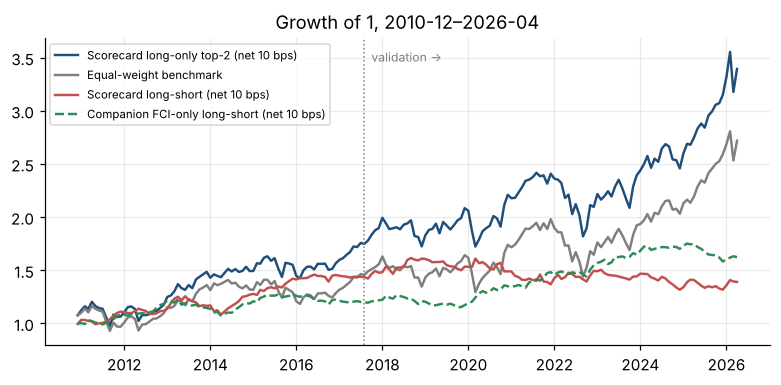

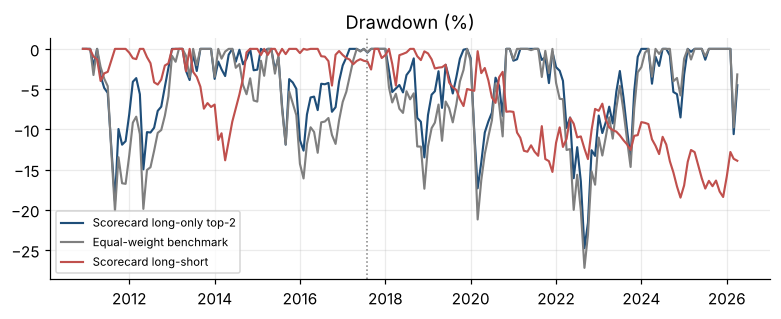

Dashed line: start of the validation window (2017-07).


In [10]:
a0 = START
cum = lambda s: (1 + s.loc[a0:].fillna(0)).cumprod()
gLO, tLO, _ = BT[('Scorecard (4-pillar)', 'LO')]; gLS, tLS, _ = BT[('Scorecard (4-pillar)', 'LS')]; gC, tC, _ = BT[('Companion (FCI-only)', 'LS')]
SER = {'Scorecard long-only top-2 (net 10 bps)': (gLO - tLO * 1e-3, '#1f4e79', '-'), 'Equal-weight benchmark': (EW, '#7f7f7f', '-'),
       'Scorecard long-short (net 10 bps)': (gLS - tLS * 1e-3, '#c0504d', '-'), 'Companion FCI-only long-short (net 10 bps)': (gC - tC * 1e-3, '#2e8b57', '--')}
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for lab, (s_, c, ls) in SER.items():
    cc = cum(s_); ax.plot(cc.index.to_timestamp(), cc.values, ls, color=c, label=lab, lw=1.6)
ax.axvline(pd.Timestamp('2017-07-31'), c='grey', ls=':', lw=1); ax.text(pd.Timestamp('2017-09-30'), ax.get_ylim()[1] * .97, 'validation →', fontsize=8, va='top', color='grey')
ax.set_title(f'Growth of 1, {START}–{AS_OF}'); ax.legend(fontsize=7.5, loc='upper left'); plt.tight_layout(); plt.savefig(CH/'cumulative_vs_benchmark.png', dpi=220, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for lab, (s_, c, ls) in list(SER.items())[:3]:
    cc = cum(s_); ax.plot(cc.index.to_timestamp(), (cc / cc.cummax() - 1).values * 100, ls, color=c, label=lab.replace(' (net 10 bps)', ''), lw=1.4)
ax.axvline(pd.Timestamp('2017-07-31'), c='grey', ls=':', lw=1); ax.set_title('Drawdown (%)'); ax.legend(fontsize=7.5, loc='lower left')
plt.tight_layout(); plt.savefig(CH/'drawdown.png', dpi=220, bbox_inches='tight'); plt.show()
print('Dashed line: start of the validation window (2017-07).')

## 6. Step 5 — Investment view (latest available data: as of 30-Apr-2026)
**Disclosure.** The supplied workbooks end on 30-Apr-2026, which is not current at the time of submission. The brief allows extra data, but the inputs here (BEst P/E, BEst EPS, Goldman Sachs and Bloomberg FCIs) are Bloomberg-proprietary, with no comparable free source. Free substitutes would mix inconsistent series. So:
* The ranking below is labelled as of its data date.
* Readings for the four markets whose files run later are shown for information only.
* Re-running this notebook on refreshed exports with the same tickers updates every output and slide.

In [11]:
t = AS_OF
CUR = pd.DataFrame({'FCI 6M easing (own-sd units)': RAWSIG['Macro'].loc[t], 'EPS revision 6M %': RAWSIG['Micro'].loc[t] * 100, 'Forward P/E': PE.loc[t],
                    'P/E ÷ peer average': PE.div(PE.mean(axis=1), axis=0).loc[t], '12M realised vol % (ann.)': -RAWSIG['Technical'].loc[t] * np.sqrt(12) * 100,
                    **{f'{p} score': Z[p].loc[t] for p in PILLARS}, **{f'{p} contribution': Z[p].loc[t] / 4 for p in PILLARS},
                    'Aggregate score': AGG.loc[t], 'Rank': RANK.loc[t].astype(int), 'Companion FCI-only rank': RANK_C.loc[t].astype(int)}).sort_values('Rank')
CUR['Scorecard call'] = CUR['Rank'].map(lambda r: 'OVERWEIGHT' if r <= 2 else ('UNDERWEIGHT' if r >= 4 else 'NEUTRAL'))
display(CUR.round(2)); CUR.to_csv(OUT/'current_scorecard.csv')
FIG['current'] = {c: {'rank': int(CUR.loc[c, 'Rank']), 'aggregate': float(CUR.loc[c, 'Aggregate score']), 'call': CUR.loc[c, 'Scorecard call'], 'companion_rank': int(CUR.loc[c, 'Companion FCI-only rank']),
                      **{p: float(CUR.loc[c, f'{p} score']) for p in PILLARS}, **{f'{p}_contrib': float(CUR.loc[c, f'{p} contribution']) for p in PILLARS},
                      'fci': float(CUR.loc[c, 'FCI 6M easing (own-sd units)']), 'eps_rev': float(CUR.loc[c, 'EPS revision 6M %']), 'pe': float(CUR.loc[c, 'Forward P/E']),
                      'pe_rel': float(CUR.loc[c, 'P/E ÷ peer average']), 'vol': float(CUR.loc[c, '12M realised vol % (ann.)'])} for c in COUNTRIES}
FIG['order'] = CUR.index.tolist()
last6 = RANK.iloc[-6:].astype(int); last6.index = last6.index.astype(str); print('Scorecard rank, last six months:'); display(last6)
FIG['rank_last6'] = {c: last6[c].tolist() for c in COUNTRIES}; FIG['rank_last6_months'] = last6.index.tolist()
gap12 = float(CUR['Aggregate score'].iloc[1] - CUR['Aggregate score'].iloc[2]); FIG['gap_rank2_rank3'] = gap12
print(f'Gap between rank 2 and rank 3 aggregate scores: {gap12:.2f}')
LATE = {}
for c in COUNTRIES:
    f = col(c, 'fci'); v = own_sd((f - f.shift(6)).to_frame()).iloc[:, 0]
    LATE[c] = {'last month in workbook': str(f.index[-1]), f'FCI 6M easing at {AS_OF}': v.loc[AS_OF], 'FCI 6M easing at last month': v.iloc[-1]}
LATE = pd.DataFrame(LATE).T; display(LATE); LATE.to_csv(OUT/'info_readings_after_asof.csv')
print('Own-history readings only; not cross-sectional scores and not used in the ranking.')

,FCI 6M easing (own-sd units),EPS revision 6M %,Forward P/E,P/E ÷ peer average,12M realised vol % (ann.),Macro score,Micro score,Valuation score,Technical score,Macro contribution,Micro contribution,Valuation contribution,Technical contribution,Aggregate score,Rank,Companion FCI-only rank,Scorecard call
US,0.010,16.470,20.700,1.230,13.330,1.090,1.270,-1.510,0.160,0.270,0.320,-0.380,0.040,0.250,1,1,OVERWEIGHT
UK,-0.460,11.690,12.890,0.760,11.290,-1.590,0.410,1.290,0.860,-0.400,0.100,0.320,0.220,0.240,2,5,OVERWEIGHT
Eurozone,-0.130,7.250,14.850,0.880,12.480,0.320,-0.390,-0.070,0.450,0.080,-0.100,-0.020,0.110,0.080,3,3,NEUTRAL
Switzerland,-0.120,1.430,18.330,1.090,13.040,0.380,-1.430,0.090,0.260,0.090,-0.360,0.020,0.060,-0.180,4,2,UNDERWEIGHT
Japan,-0.220,10.270,17.610,1.040,18.770,-0.200,0.150,0.200,-1.720,-0.050,0.040,0.050,-0.430,-0.390,5,4,UNDERWEIGHT


Scorecard rank, last six months:


,US,Eurozone,UK,Switzerland,Japan
2025-11,4,3,1,5,2
2025-12,4,3,1,5,2
2026-01,3,4,1,5,2
2026-02,4,3,1,5,2
2026-03,4,3,1,5,2
2026-04,1,3,2,4,5


Gap between rank 2 and rank 3 aggregate scores: 0.17


,last month in workbook,FCI 6M easing at 2026-04,FCI 6M easing at last month
US,2026-04,0.011,0.011
Eurozone,2026-06,-0.140,-0.094
UK,2026-07,-0.484,-0.340
Switzerland,2026-07,-0.115,0.139
Japan,2026-06,-0.218,0.175


Own-history readings only; not cross-sectional scores and not used in the ranking.


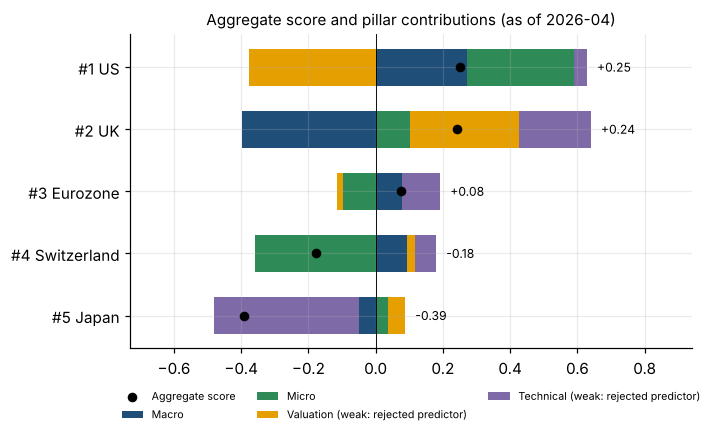

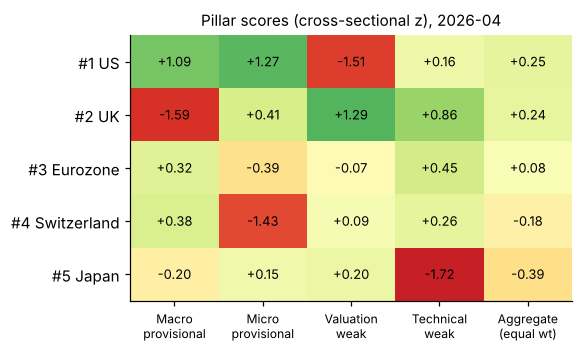

In [12]:
order = CUR.index[::-1]; bp = np.zeros(5); bn = np.zeros(5)
fig, ax = plt.subplots(figsize=(6.6, 4.1))
for p in PILLARS:
    v = CUR.loc[order, f'{p} contribution'].values; lab = p + ('' if FIG['classification'][p] == 'PROVISIONAL' else ' (weak: rejected predictor)')
    ax.barh(np.arange(5), np.where(v > 0, v, 0), left=bp, color=PCOL[p], label=lab, height=.6); ax.barh(np.arange(5), np.where(v < 0, v, 0), left=bn, color=PCOL[p], height=.6)
    bp += np.where(v > 0, v, 0); bn += np.where(v < 0, v, 0)
ax.scatter(CUR.loc[order, 'Aggregate score'], np.arange(5), color='k', zorder=5, s=28, label='Aggregate score')
for i, c in enumerate(order): ax.text(max(bp[i], 0) + .03, i, f'{CUR.loc[c, "Aggregate score"]:+.2f}', va='center', fontsize=8)
ax.set_yticks(np.arange(5)); ax.set_yticklabels([f'#{int(CUR.loc[c, "Rank"])} {c}' for c in order]); ax.axvline(0, c='k', lw=.6)
ax.set_title(f'Aggregate score and pillar contributions (as of {AS_OF})', fontsize=10); ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax.set_xlim(bn.min() - .25, bp.max() + .3); plt.tight_layout(); plt.savefig(CH/'pillar_contributions.png', dpi=220, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(5.4, 3.3))
hm = CUR[[f'{p} score' for p in PILLARS] + ['Aggregate score']]; ax.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(5)); ax.set_xticklabels([f'{p}\n{"provisional" if FIG["classification"][p] == "PROVISIONAL" else "weak"}' for p in PILLARS] + ['Aggregate\n(equal wt)'], fontsize=8)
ax.set_yticks(range(5)); ax.set_yticklabels([f'#{int(CUR.loc[c, "Rank"])} {c}' for c in CUR.index])
for i in range(5):
    for j in range(5): ax.text(j, i, f'{hm.values[i, j]:+.2f}', ha='center', va='center', fontsize=8.5)
ax.set_title(f'Pillar scores (cross-sectional z), {AS_OF}', fontsize=10); ax.grid(False)
plt.tight_layout(); plt.savefig(CH/'pillar_heatmap.png', dpi=220, bbox_inches='tight'); plt.show()

## 7. Exports and slide figures

In [13]:
panel = pd.concat({'BEst_PE': PE, 'EPS_fwd': EPS, 'FCI_oriented_easier_plus': FCI, 'USD_per_local': FX, 'implied_index_local': PX, 'implied_index_usd': PX_USD}, axis=1)
panel.index = panel.index.astype(str); panel.to_csv(OUT/'input_monthly_panel.csv')
SIGL = pd.concat({p: RAWSIG[p] for p in PILLARS}, axis=1); SIGL.index = SIGL.index.astype(str); SIGL.to_csv(OUT/'signals_raw_monthly.csv')
PSC = pd.concat({**{p: Z[p] for p in PILLARS}, 'Aggregate': AGG, 'Rank': RANK, 'Companion_FCI_only': COMP}, axis=1); PSC.index = PSC.index.astype(str); PSC.to_csv(OUT/'pillar_scores_monthly.csv')
json.dump(FIG, open(OUT/'ppt_figures.json', 'w'), indent=2, default=float)
print('Outputs in', OUT.relative_to(ROOT)); print(sorted(p.name for p in OUT.glob('*.csv')))

Outputs in output/v14
['aggregate_score_ic.csv', 'backtest_monthly.csv', 'backtest_pillar_attribution.csv', 'backtest_summary.csv', 'country_contributions.csv', 'current_scorecard.csv', 'info_readings_after_asof.csv', 'input_monthly_panel.csv', 'pillar_scores_monthly.csv', 'predictive_power.csv', 'scorecard_history.csv', 'signal_classification.csv', 'signal_definitions.csv', 'signals_raw_monthly.csv', 'slide_number_registry.csv']


## 8. Methodology and limitations document (generated from the results above)

In [14]:
f2 = lambda x: f'{x:+.2f}'; bt = FIG['bt']
ic = lambda p, w, h: PP.loc[(p, h, w), 'IC']
doc = f"""# Developed-Markets Equity Scorecard — Methodology and Limitations

Generated by `notebook/Markets_Scorecard_v14_FINAL.ipynb`. Every number below comes from `output/v14/`.

## Data
- Only the supplied Bloomberg workbooks. Monthly panel {IDX[0]} → {AS_OF} (last observation in each month).
- **As-of date {AS_OF}**: the last month in which all five markets report (the US workbook ends 30-Apr-2026).
- **Index level** = BEst forward P/E × forward EPS. This is an identity. The US matches published S&P 500 monthly returns to {FIG['spx_check_mad_pp']:.2f} pp on average across eight checked months.
- The supplied "Price" workbook contains P/E ratios, not index levels.
- Returns are USD **price** returns; dividends are not available.

## Signals (one per pillar; cross-sectional z-score each month; higher = more attractive)
""" + "\n".join(f"- **{p} — {SIGDOC.loc[p, 'indicator']}**: {SIGDOC.loc[p, 'construction']}. *Rationale:* {SIGDOC.loc[p, 'economic rationale']} *Source:* {SIGDOC.loc[p, 'data source']}." for p in PILLARS) + f"""
- The technical signal's R² on EPS revisions is {FIG['tech_r2_on_eps']:.1%}, so it carries price-path information rather than restating earnings.

## Predictive power
- **Test:** monthly Spearman rank IC against the next 3M and 6M USD return relative to the 5-market mean.
- **Windows:** discovery (signal months to 2016-12), then a 6-month embargo, then validation (2017-07 onward).
- **Inference:** 95% moving-block bootstrap CI, HAC t, and block-permutation p.

| Pillar | Disc IC 3M | Val IC 3M | Disc IC 6M | Val IC 6M | Class |
|---|---|---|---|---|---|
""" + "\n".join(f"| {p} | {f2(ic(p, 'discovery', '3M'))} | {f2(ic(p, 'validation', '3M'))} | {f2(ic(p, 'discovery', '6M'))} | {f2(ic(p, 'validation', '6M'))} | {FIG['classification'][p]} |" for p in PILLARS) + f"""

**Multiple testing:** these indicators were selected during research that tested many alternatives.
- The selection-adjusted p-values for Macro and Micro are 0.16–0.20 (v11 audit).
- A nominal 5% HAC test rejects 6–9% of the time in this sample under a true null.
- The validation window has been examined repeatedly.
- **No pillar is statistically significant.**

## Scorecard
- **Aggregate** = equal-weight average of the four pillar z-scores (25% each). A pillar's contribution = ¼ × its z.
- **Ranking:** 1–5 by aggregate. Calls: ranks 1–2 overweight, 3 neutral, 4–5 underweight.
- **Why equal weights:** the brief requires four pillars, and no pillar has validated evidence. Estimated weights would be in-sample optimisation.
- **Predictive power of the aggregate:** validation IC {f2(FIG['agg_ic']['validation 3M'])} (3M) and {f2(FIG['agg_ic']['validation 6M'])} (6M), versus {f2(FIG['agg_ic']['discovery 3M'])} and {f2(FIG['agg_ic']['discovery 6M'])} in discovery.
- **Companion model:** an FCI-only ranking, reported separately.

## Backtest
**Rules (not optimised):**
- Monthly signal, 6-month overlapping tranches.
- Long-only: 50% in each top-2 market vs a 20% equal-weight benchmark.
- Long-short: ±50% top-2 / bottom-2.
- Drift-accurate turnover; one-way costs on a 0/5/10/20 bps grid.

**Results, full period {FIG['bt_window']['full']}, net of 10 bps:**

| | Scorecard long-only | EW benchmark | Scorecard long-short | FCI-only long-short |
|---|---|---|---|---|
| Return % p.a. | {bt['full']['LO_ret']:.1f} | {bt['full']['EW_ret']:.1f} | {bt['full']['LS_ret']:.1f} | {bt['full']['C_LS_ret']:.1f} |
| Volatility % p.a. | {bt['full']['LO_vol']:.1f} | {bt['full']['EW_vol']:.1f} | {bt['full']['LS_vol']:.1f} | {bt['full']['C_LS_vol']:.1f} |
| Sharpe | {bt['full']['LO_sharpe']:.2f} | {bt['full']['EW_sharpe']:.2f} | {bt['full']['LS_sharpe']:.2f} | {bt['full']['C_LS_sharpe']:.2f} |
| Max drawdown % | {bt['full']['LO_dd']:.1f} | {bt['full']['EW_dd']:.1f} | {bt['full']['LS_dd']:.1f} | {bt['full']['C_LS_dd']:.1f} |
| Validation Sharpe | {bt['validation']['LO_sharpe']:.2f} | {bt['validation']['EW_sharpe']:.2f} | {bt['validation']['LS_sharpe']:.2f} | {bt['validation']['C_LS_sharpe']:.2f} |

**Why the composite fails after 2017.** Each pillar alone, with the same rules, earns a validation long-short Sharpe of:
- Macro {FIG['pillar_alone_sharpe']['Macro']['validation']:+.2f}
- Micro {FIG['pillar_alone_sharpe']['Micro']['validation']:+.2f}
- Valuation {FIG['pillar_alone_sharpe']['Valuation']['validation']:+.2f}
- Technical {FIG['pillar_alone_sharpe']['Technical']['validation']:+.2f}

The two rejected pillars cancel the two that work.

## Investment view (as of {AS_OF})
""" + "\n".join(f"- #{FIG['current'][c]['rank']} **{c}**: aggregate {FIG['current'][c]['aggregate']:+.2f}, {FIG['current'][c]['call']} (FCI-only companion rank {FIG['current'][c]['companion_rank']})" for c in FIG['order']) + f"""

**Conviction is low:**
- Ranks 1 and 2 are near-tied ({FIG['current'][FIG['order'][0]]['aggregate']:+.2f} vs {FIG['current'][FIG['order'][1]]['aggregate']:+.2f}). The gap between rank 2 (overweight) and rank 3 (neutral) is {FIG['gap_rank2_rank3']:.2f}.
- The ranking changed sharply in the final month.
- The companion FCI-only model disagrees on the UK and Switzerland.

## Limitations
1. **Stale data.** The data end 30-Apr-2026; the readings are not current. The brief allows extra data, but the inputs (BEst P/E and EPS, Goldman Sachs and Bloomberg FCIs) are proprietary, with no comparable free source. Finance data hosts are also blocked from the build environment. To refresh, re-export the same tickers and re-run the notebook.
2. **Price return only.** No dividends, which understates high-yield markets.
3. **Point-in-time unknown.** Whether the consensus EPS and P/E history are point-in-time snapshots cannot be verified.
4. **Switzerland uses euro-area series.** Its FCI is the euro-area GSEAFCI, and its credit spread duplicates the euro index.
5. **US EPS field differs.** The US uses `Monthly_EPS`; the other four use BEst EPS.
6. **Small sample.** Five markets and about 17 independent 6-month periods in validation. The research history is long (v1–v13), so the results carry selection risk.
7. **Benchmark limits.** The benchmark is equal-weight because no market-cap data were supplied. Long-short Sharpe uses rf = 0.
"""
(OUT/'METHODOLOGY_AND_LIMITATIONS.md').write_text(doc, encoding='utf8'); print(doc[:1500])

# Developed-Markets Equity Scorecard — Methodology and Limitations

Generated by `notebook/Markets_Scorecard_v14_FINAL.ipynb`. Every number below comes from `output/v14/`.

## Data
- Only the supplied Bloomberg workbooks. Monthly panel 2005-12 → 2026-04 (last observation in each month).
- **As-of date 2026-04**: the last month in which all five markets report (the US workbook ends 30-Apr-2026).
- **Index level** = BEst forward P/E × forward EPS. This is an identity. The US matches published S&P 500 monthly returns to 0.04 pp on average across eight checked months.
- The supplied "Price" workbook contains P/E ratios, not index levels.
- Returns are USD **price** returns; dividends are not available.

## Signals (one per pillar; cross-sectional z-score each month; higher = more attractive)
- **Macro — FCI 6M easing**: (FCI_t − FCI_t−6) ÷ expanding sd of that 6M change; FCI oriented so higher = easier. *Rationale:* Easier financing conditions (tighter spreads, lower rates/vol, weaker curr